<a href="https://colab.research.google.com/github/thejuthejaskg-lab/Machine_Learning/blob/main/loan_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. import libraries

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import LabelEncoder,StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,precision_score,recall_score, confusion_matrix, classification_report,f1_score

2.load the dataset

In [ ]:
df = pd.read_csv("/content/loan_data.csv")
print("--- Dataset Head ---")
print(df.head(10))

--- Dataset Head ---
    Loan_ID Gender Married Dependents     Education Self_Employed  \
0  LP001002   Male      No          0      Graduate            No   
1  LP001003   Male     Yes          1      Graduate            No   
2  LP001005   Male     Yes          0      Graduate           Yes   
3  LP001006   Male     Yes          0  Not Graduate            No   
4  LP001008   Male      No          0      Graduate            No   
5  LP001011   Male     Yes          2      Graduate           Yes   
6  LP001013   Male     Yes          0  Not Graduate            No   
7  LP001014   Male     Yes         3+      Graduate            No   
8  LP001018   Male     Yes          2      Graduate            No   
9  LP001020   Male     Yes          1      Graduate            No   

   ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  \
0             5849                0.0         NaN             360.0   
1             4583             1508.0       128.0             360.0   
2     

3.Explore the dataset


In [ ]:
print("Shape:", df.shape)
print("Columns:", list(df.columns))
df.info()

Shape: (981, 13)
Columns: ['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 981 entries, 0 to 980
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            981 non-null    object 
 1   Gender             957 non-null    object 
 2   Married            978 non-null    object 
 3   Dependents         956 non-null    object 
 4   Education          981 non-null    object 
 5   Self_Employed      926 non-null    object 
 6   ApplicantIncome    981 non-null    int64  
 7   CoapplicantIncome  981 non-null    float64
 8   LoanAmount         954 non-null    float64
 9   Loan_Amount_Term   961 non-null    float64
 10  Credit_History     902 non-null    float64
 11  Property_Area      981 non-null    obje

4.handle null Values and 5.duplicates and drop it

In [ ]:
print("--- Null Values Before Drop ---")
print(df.isnull().sum())
df = df.dropna()
print("\n--- Null Values After Drop ---")
print(df.isnull().sum())
print()
print(f"Duplicates before: {df.duplicated().sum()}")
df = df.drop_duplicates()
print(f"Duplicates after:  {df.duplicated().sum()}")
print()

--- Null Values Before Drop ---
Loan_ID                0
Gender                24
Married                3
Dependents            25
Education              0
Self_Employed         55
ApplicantIncome        0
CoapplicantIncome      0
LoanAmount            27
Loan_Amount_Term      20
Credit_History        79
Property_Area          0
Loan_Status          367
dtype: int64

--- Null Values After Drop ---
Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64

Duplicates before: 0
Duplicates after:  0



6. detect ouliers

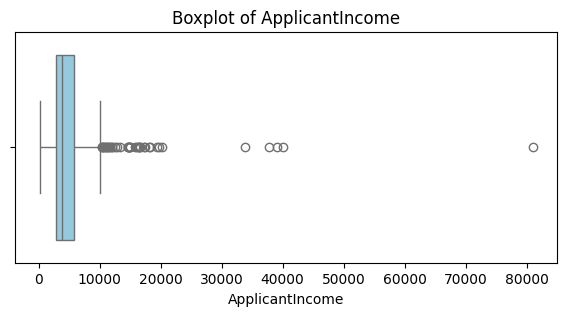

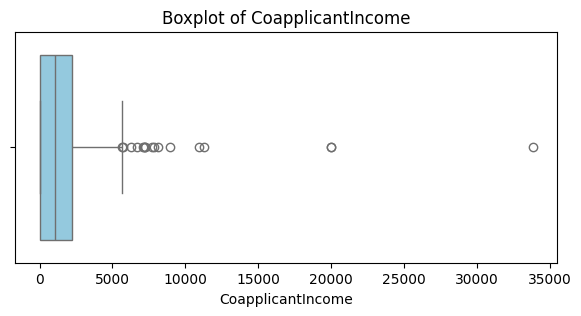

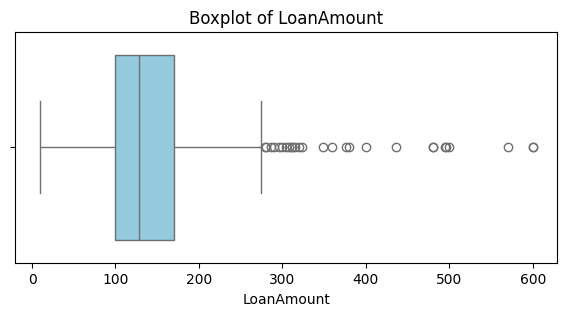

In [ ]:
for col in ["ApplicantIncome", "CoapplicantIncome", "LoanAmount"]:
  plt.figure(figsize=(7, 3))
  sns.boxplot(x=df[col], color="skyblue")
  plt.title(f"Boxplot of {col}")
  plt.show()

Data preparation and model training

7. drop loan _id and encode with separate labelencoders

In [ ]:
df = df.drop(columns=["Loan_ID"])
cat_cols = ["Gender", "Married", "Dependents", "Education", "Self_Employed", "Property_Area", "Loan_Status"]
encoders = {}
for col in cat_cols:
  encoders[col] = LabelEncoder()
  df[col] = encoders[col].fit_transform(df[col])
df.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
1,1,1,1,0,0,4583,1508.0,128.0,360.0,1.0,0,0
2,1,1,0,0,1,3000,0.0,66.0,360.0,1.0,2,1
3,1,1,0,1,0,2583,2358.0,120.0,360.0,1.0,2,1
4,1,0,0,0,0,6000,0.0,141.0,360.0,1.0,2,1
5,1,1,2,0,1,5417,4196.0,267.0,360.0,1.0,2,1


8. separate features and target

In [ ]:
features = ["Gender", "Married", "Dependents", "Education", "Self_Employed", "ApplicantIncome", "CoapplicantIncome", "LoanAmount", "Loan_Amount_Term", "Credit_History", "Property_Area"]
x = df[features]
y = df["Loan_Status"]
print("x shape:", x.shape)
print("y shape:", y.shape)

x shape: (480, 11)
y shape: (480,)


9. split the dataset

In [ ]:
x_train, x_test, y_train, y_test = train_test_split( x, y, test_size=0.2, random_state=42, stratify=y)
print(x_train.shape, x_test.shape, y_train.shape, y_test.shape)

(384, 11) (96, 11) (384,) (96,)


10. feature scaling

In [ ]:
scale_cols = ["ApplicantIncome", "CoapplicantIncome", "LoanAmount", "Loan_Amount_Term"]
scaler = StandardScaler()
x_train = x_train.copy()
x_test = x_test.copy()
x_train[scale_cols] = scaler.fit_transform(x_train[scale_cols])
x_test[scale_cols] = scaler.transform(x_test[scale_cols])
x_train.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area
475,1,1,2,0,1,1.875918,-0.192722,0.062059,0.268268,1.0,0
456,1,1,0,0,0,-0.203807,-0.561999,-0.354426,0.268268,1.0,2
342,1,1,1,1,0,-0.160762,-0.114424,0.166181,0.268268,1.0,2
440,1,0,0,0,0,-0.312863,1.282200,0.543620,0.268268,1.0,1
250,1,1,0,1,0,-0.651771,0.854655,0.725833,0.268268,0.0,1


11. train logistic regression

In [ ]:
lr = LogisticRegression(max_iter=1000)
lr.fit(x_train, y_train)
y_pred_lr = lr.predict(x_test)
print(y_pred_lr)

[1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 0 1 0 0 1 1 1 1 1
 1 1 0 1 1 0 1 1 1 0 1 0 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 0 1 1 1 0 1 1 1 1 0
 1 0 0 0 0 1 1 1 1 1 1 1 0 1 1 1 1 1 0 0 1 1]


12.evaluate logistic regression

Accuracy : 0.8333333333333334
Precision: 0.8289473684210527
Recall   : 0.9545454545454546
F1 Score : 0.8873239436619719
Confusion Matrix:
 [[17 13]
 [ 3 63]]


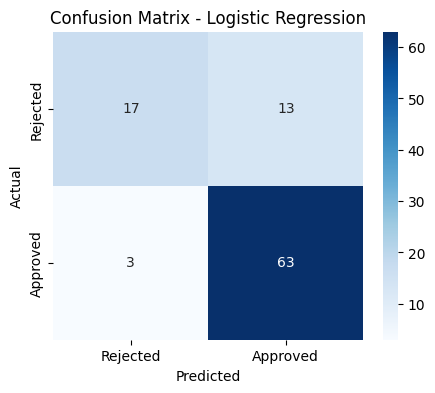

In [ ]:
acc_lr = accuracy_score(y_test, y_pred_lr)
prec_lr = precision_score(y_test, y_pred_lr)
rec_lr = recall_score(y_test, y_pred_lr)
f1_lr = f1_score(y_test, y_pred_lr)
print("Accuracy :", acc_lr)
print("Precision:", prec_lr)
print("Recall   :", rec_lr)
print("F1 Score :", f1_lr)
cm_lr = confusion_matrix(y_test, y_pred_lr)
print("Confusion Matrix:\n", cm_lr)
plt.figure(figsize=(5, 4))
sns.heatmap(cm_lr, annot=True, fmt="d", cmap="Blues", xticklabels=["Rejected", "Approved"], yticklabels=["Rejected", "Approved"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

13. train decision treee

In [ ]:
dt = DecisionTreeClassifier(random_state=42)
dt.fit(x_train, y_train)
y_pred_dt = dt.predict(x_test)
print(y_pred_dt)

[1 1 1 1 1 1 1 0 0 1 1 1 0 1 1 1 0 1 1 0 0 1 1 1 1 0 0 1 1 1 0 0 1 1 1 1 1
 1 1 1 0 1 0 1 1 1 0 1 0 0 1 1 1 1 1 1 0 1 1 1 0 0 1 0 0 1 1 0 0 0 1 1 0 0
 1 0 0 0 0 0 0 0 1 0 0 1 0 1 1 1 1 1 0 0 1 1]


14. evaluate decision tree

Accuracy : 0.7395833333333334
Precision: 0.847457627118644
Recall   : 0.7575757575757576
F1 Score : 0.8
Confusion Matrix:
 [[21  9]
 [16 50]]


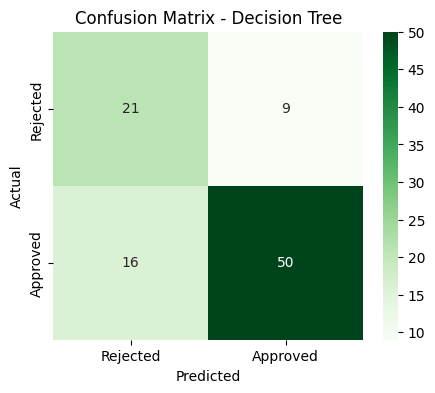

In [ ]:
acc_dt = accuracy_score(y_test, y_pred_dt)
prec_dt = precision_score(y_test, y_pred_dt)
rec_dt = recall_score(y_test, y_pred_dt)
f1_dt = f1_score(y_test, y_pred_dt)
print("Accuracy :", acc_dt)
print("Precision:", prec_dt)
print("Recall   :", rec_dt)
print("F1 Score :", f1_dt)
cm_dt = confusion_matrix(y_test, y_pred_dt)
print("Confusion Matrix:\n", cm_dt)
plt.figure(figsize=(5, 4))
sns.heatmap(cm_dt, annot=True, fmt="d", cmap="Greens", xticklabels=["Rejected", "Approved"], yticklabels=["Rejected", "Approved"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Decision Tree")
plt.show()

15.visualizde and download decision tree

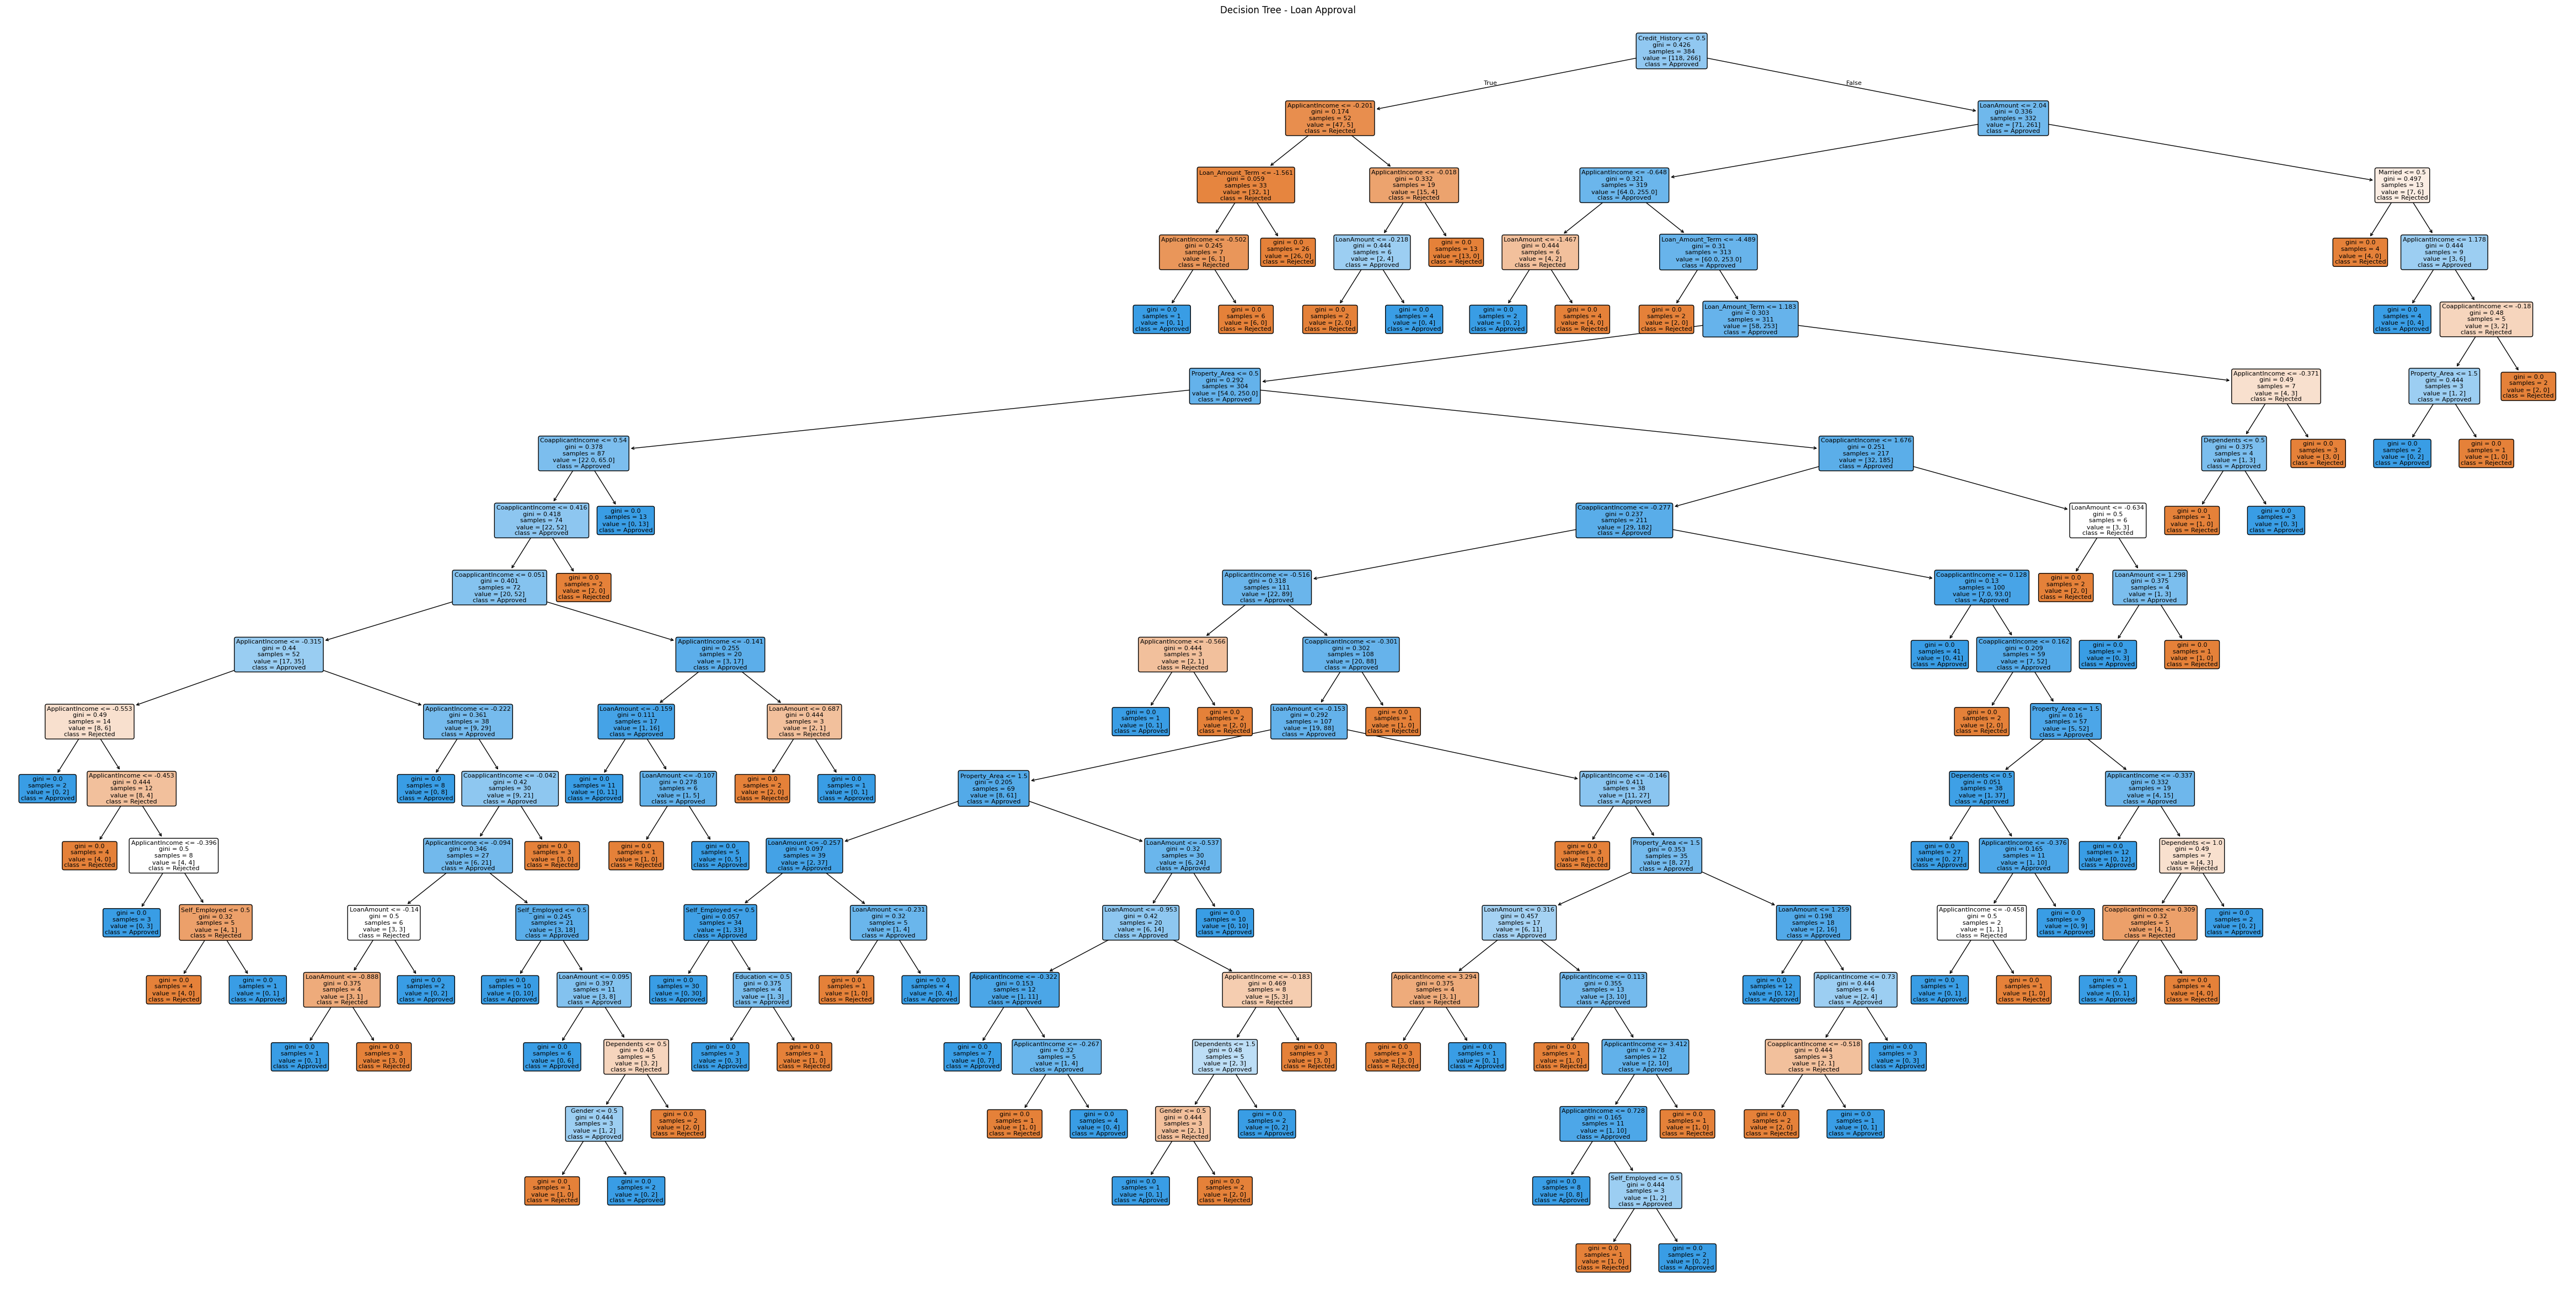

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

features = ["Gender", "Married", "Dependents", "Education", "Self_Employed", "ApplicantIncome", "CoapplicantIncome", "LoanAmount", "Loan_Amount_Term", "Credit_History", "Property_Area"]
plt.figure(figsize=(60, 30))
plot_tree(dt,
          feature_names=features,
          class_names=["Rejected", "Approved"],
          filled=True,
          rounded=True,
          fontsize=8)
plt.title("Decision Tree - Loan Approval")
plt.savefig("decision_tree.svg", format="svg", bbox_inches="tight")
plt.show()
from google.colab import files
files.download("decision_tree.svg")

16.train random forest

In [ ]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(x_train, y_train)
y_pred_rf = rf.predict(x_test)
print(y_pred_rf)

[1 1 1 1 1 1 1 0 1 1 1 1 0 1 1 1 1 0 1 1 1 1 1 1 1 0 0 1 0 1 0 0 1 1 1 1 1
 1 1 1 1 1 0 1 1 1 0 1 0 1 1 1 1 1 1 1 1 0 1 1 0 0 1 1 0 1 1 0 0 1 1 1 1 0
 1 0 0 0 0 1 0 1 0 0 1 1 0 1 1 1 1 1 0 0 1 1]


17.evaluate random forest

Accuracy : 0.8125
Precision: 0.8529411764705882
Recall   : 0.8787878787878788
F1 Score : 0.8656716417910447
Confusion Matrix:
 [[20 10]
 [ 8 58]]


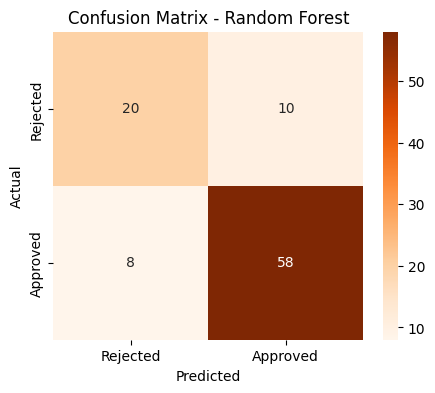

In [ ]:
acc_rf = accuracy_score(y_test, y_pred_rf)
prec_rf = precision_score(y_test, y_pred_rf)
rec_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
print("Accuracy :", acc_rf)
print("Precision:", prec_rf)
print("Recall   :", rec_rf)
print("F1 Score :", f1_rf)
cm_rf = confusion_matrix(y_test, y_pred_rf)
print("Confusion Matrix:\n", cm_rf)
plt.figure(figsize=(5, 4))
sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Oranges", xticklabels=["Rejected", "Approved"], yticklabels=["Rejected", "Approved"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Random Forest")
plt.show()

18. compare all three models

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.833333,0.828947,0.954545,0.887324
1,Decision Tree,0.739583,0.847458,0.757576,0.800000
2,Random Forest,0.812500,0.852941,0.878788,0.865672


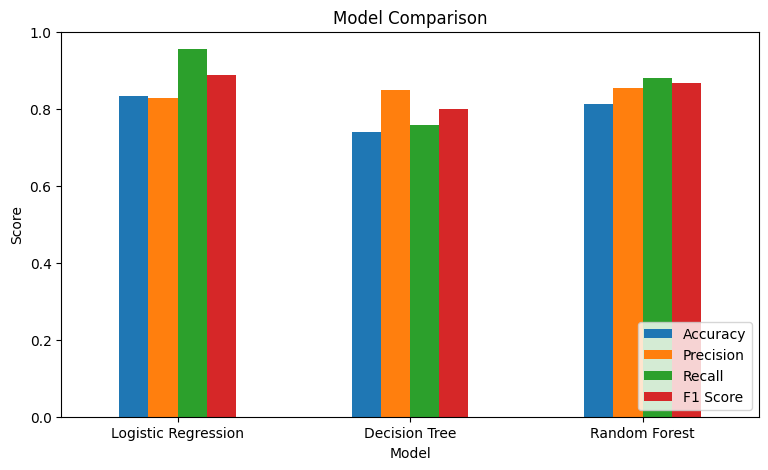

In [ ]:
comparison = pd.DataFrame({ "Model": ["Logistic Regression", "Decision Tree", "Random Forest"], "Accuracy": [acc_lr, acc_dt, acc_rf], "Precision": [prec_lr, prec_dt, prec_rf], "Recall": [rec_lr, rec_dt, rec_rf], "F1 Score": [f1_lr, f1_dt, f1_rf] })
display(comparison)
comparison.set_index("Model").plot(kind="bar", figsize=(9, 5), ylim=(0, 1), rot=0)
plt.ylabel("Score")
plt.title("Model Comparison")
plt.legend(loc="lower right")
plt.show()